In [1]:
import pandas as pd

df = pd.read_csv("online_shoppers_intention.csv")

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
df.shape

(12330, 18)

In [3]:
df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

In [4]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(125)

## Exploratory Data Analysis (EDA)

### Target Variable: Revenue

In [6]:
df["Revenue"].value_counts()

Revenue
False    10422
True      1908
Name: count, dtype: int64

### Purchase Conversion Distribution

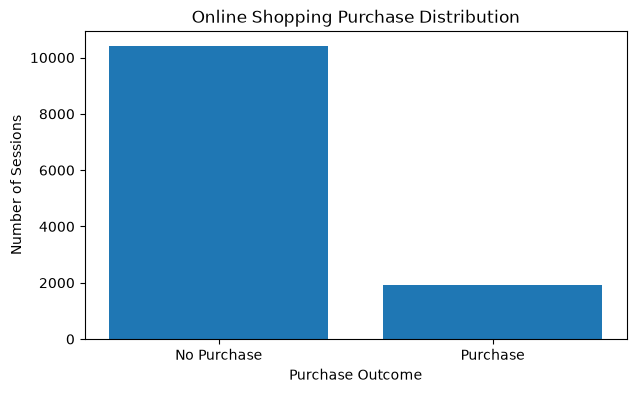

In [7]:
import matplotlib.pyplot as plt

purchase_counts = df["Revenue"].value_counts()

plt.figure(figsize=(7, 4))

plt.bar(
    ["No Purchase", "Purchase"],
    [purchase_counts[False], purchase_counts[True]]
)

plt.title("Online Shopping Purchase Distribution")
plt.xlabel("Purchase Outcome")
plt.ylabel("Number of Sessions")

plt.show()

¿Los visitantes recurrentes tienen una tasa de compra diferente a los visitantes nuevos?

### Purchase Conversion by Visitor Type

In [8]:
conversion_by_visitor = df.groupby("VisitorType")["Revenue"].mean() * 100

conversion_by_visitor

VisitorType
New_Visitor          24.911452
Other                18.823529
Returning_Visitor    13.932329
Name: Revenue, dtype: float64

Los visitantes nuevos presentan una tasa de conversión mayor que los recurrentes: 24,91 % frente a 13,93 %

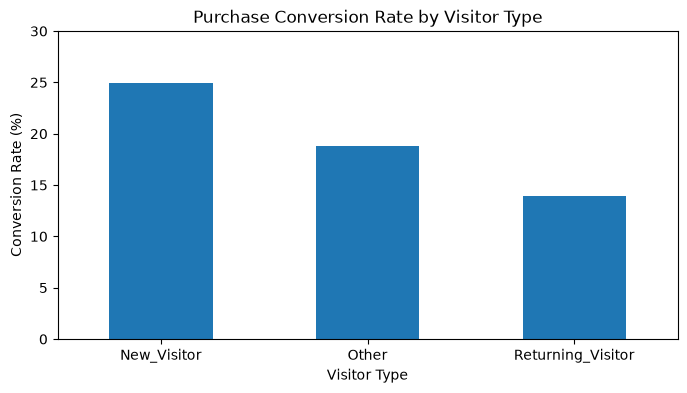

In [9]:
plt.figure(figsize=(8, 4))

conversion_by_visitor.sort_values(ascending=False).plot(kind="bar")

plt.title("Purchase Conversion Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 30)

plt.show()

¿cuántas sesiones corresponden a cada tipo de visitante?

In [10]:
df["VisitorType"].value_counts()

VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

Conclusión: aunque los visitantes recurrentes representan la mayoría de las sesiones, los visitantes nuevos tienen una mayor probabilidad observada de terminar comprando.

¿Las sesiones que terminan en compra visitan más páginas de productos?

### Product Page Visits and Purchase Behaviour

In [11]:
df.groupby("Revenue")["ProductRelated"].mean()

Revenue
False    28.714642
True     48.210168
Name: ProductRelated, dtype: float64

Media de páginas de productos visitadas por sesión
Sin compra
28,7
Páginas visitadas

Con compra
48,2
Páginas visitadas


Las sesiones que terminan en compra registran aproximadamente un 68 % más de páginas de productos visitadas, de media.

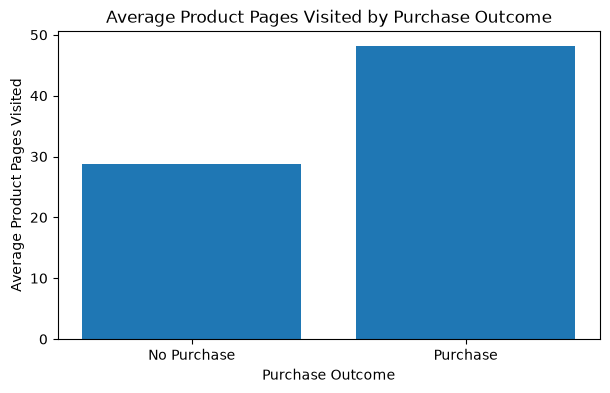

In [12]:
avg_product_pages = df.groupby("Revenue")["ProductRelated"].mean()

plt.figure(figsize=(7, 4))

plt.bar(
    ["No Purchase", "Purchase"],
    [avg_product_pages[False], avg_product_pages[True]]
)

plt.title("Average Product Pages Visited by Purchase Outcome")
plt.xlabel("Purchase Outcome")
plt.ylabel("Average Product Pages Visited")

plt.show()

Las sesiones que terminan en compra visitan, de media, unas 48 páginas de productos, frente a las 29 páginas de las sesiones sin compra

¿Las personas que compran también pasan más tiempo consultando productos?

### Product Browsing Time and Purchase Behaviour

In [13]:
df.groupby("Revenue")["ProductRelated_Duration"].mean()

Revenue
False    1069.987809
True     1876.209615
Name: ProductRelated_Duration, dtype: float64

Tiempo medio dedicado a páginas de productos
Sin compra
17,8 min
1.070 segundos

Con compra
31,3 min
1.876 segundos

Las sesiones que terminaron en compra dedicaron aproximadamente un 75 % más de tiempo a consultar productos.

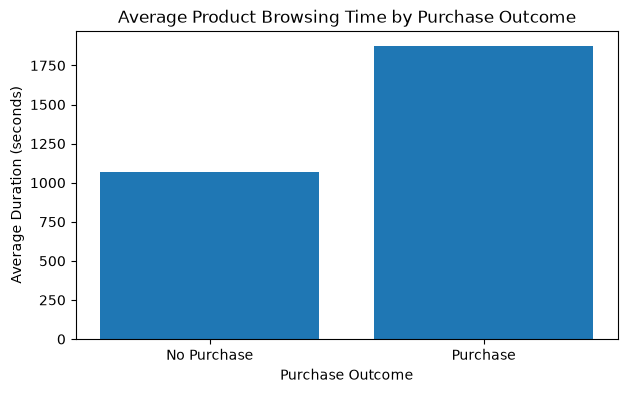

In [14]:
avg_duration = df.groupby("Revenue")["ProductRelated_Duration"].mean()

plt.figure(figsize=(7, 4))

plt.bar(
    ["No Purchase", "Purchase"],
    [avg_duration[False], avg_duration[True]]
)

plt.title("Average Product Browsing Time by Purchase Outcome")
plt.xlabel("Purchase Outcome")
plt.ylabel("Average Duration (seconds)")

plt.show()

## 3. Preparación de los datos

### 3.1. Separación de variables predictoras y variable objetivo

Separamos las variables predictoras (X) de la variable objetivo (y).

Nuestro objetivo es predecir si una sesión de navegación en una tienda online terminará en una compra.

La variable objetivo es `Revenue`:
- True: el usuario realizó una compra.
- False: el usuario no realizó una compra.

In [15]:
X = df.drop(columns=["Revenue"])
y = df["Revenue"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (12330, 17)
Target: (12330,)


X: 12.330 sesiones y 17 variables predictoras.
y: 12.330 resultados que indican si hubo compra o no.

### 3.2. División de los datos en entrenamiento y prueba

Dividimos el conjunto de datos en un 80 % para entrenamiento y un 20 % para prueba.

Utilizamos una división estratificada para mantener aproximadamente la misma proporción de sesiones con compra y sin compra en ambos conjuntos.

El conjunto de prueba nos permitirá evaluar el rendimiento del modelo con datos que no ha utilizado durante el entrenamiento.

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (9864, 17)
Prueba: (2466, 17)


### 3.3. Preprocesamiento de las variables

Para entrenar modelos de aprendizaje automático, transformamos las variables categóricas en valores numéricos mediante One-Hot Encoding.

También estandarizamos las variables numéricas, ya que modelos basados en distancias, como KNN, son sensibles a las diferencias de escala.

El preprocesamiento se ajustará únicamente con los datos de entrenamiento para evitar fugas de información hacia el conjunto de prueba.

In [17]:
from funciones import crear_preprocesador

preprocesador = crear_preprocesador(X_train)

print(preprocesador)

ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                 ['Administrative', 'Administrative_Duration',
                                  'Informational', 'Informational_Duration',
                                  'ProductRelated', 'ProductRelated_Duration',
                                  'BounceRates', 'ExitRates', 'PageValues',
                                  'SpecialDay', 'OperatingSystems', 'Browser',
                                  'Region', 'TrafficType', 'Weekend']),
                                ('categoricas',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Month', 'VisitorType'])])


15 variables numéricas o booleanas, que pasarán por StandardScaler.

2 variables categóricas, Month y VisitorType, que pasarán por OneHotEncoder.

## 4. Construcción de modelos de Machine Learning

### 4.1. Modelo K-Nearest Neighbors (KNN)

Entrenamos un modelo KNN para predecir si una sesión de navegación terminará en compra.

KNN clasifica una observación teniendo en cuenta las observaciones más cercanas según sus características.

Utilizamos un Pipeline para integrar el preprocesamiento y el entrenamiento, evitando fugas de información.

En este primer modelo excluimos PageValues por precaución ante una posible fuga de información relacionada con las conversiones.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# Excluir PageValues
X_train_knn = X_train.drop(columns=["PageValues"])
X_test_knn = X_test.drop(columns=["PageValues"])

# Crear un preprocesador para las variables restantes
preprocesador_knn = crear_preprocesador(X_train_knn)

# Crear el modelo
modelo_knn = Pipeline(steps=[
    ("preprocesamiento", preprocesador_knn),
    ("modelo", KNeighborsClassifier())
])

# Entrenar
modelo_knn.fit(X_train_knn, y_train)

print("Modelo KNN entrenado correctamente")

Modelo KNN entrenado correctamente


### 4.2. Evaluación del modelo KNN

Evaluamos el modelo utilizando el conjunto de prueba, formado por el 20 % de las sesiones.

Analizamos las siguientes métricas:

- Accuracy: porcentaje total de predicciones correctas.
- Precision: proporción de compras predichas que realmente fueron compras.
- Recall: proporción de compras reales que el modelo consigue identificar.
- F1-score: medida que combina Precision y Recall.

Dado que nuestro conjunto de datos está desequilibrado, prestaremos especial atención a las métricas de la clase positiva (compra).

In [19]:
import importlib
import funciones

importlib.reload(funciones)

funciones.evaluar_modelo(modelo_knn, X_test_knn, y_test)

Accuracy: 0.8212

Informe de clasificación:
              precision    recall  f1-score   support

       False       0.86      0.95      0.90      2084
        True       0.32      0.14      0.19       382

    accuracy                           0.82      2466
   macro avg       0.59      0.54      0.55      2466
weighted avg       0.77      0.82      0.79      2466


Matriz de confusión:
[[1973  111]
 [ 330   52]]


ACCURACY
82,12 %
Aciertos totales

RECALL COMPRA
13,61 %
Compradores detectados

F1 COMPRA
19 %
Equilibrio entre métricas

### 4.3. Interpretación de los resultados de KNN

El primer modelo KNN obtiene una exactitud (Accuracy) del 82,12 %.

Sin embargo, al analizar la clase positiva (compra), observamos un rendimiento limitado:

- Precision: 32 %.
- Recall: 14 % aproximadamente.
- F1-score: 19 %.

De las 382 sesiones que finalizaron en compra, el modelo identificó correctamente únicamente 52 y clasificó erróneamente 330 como sesiones sin compra.

Estos resultados muestran que el Accuracy no es suficiente para evaluar el rendimiento del modelo, especialmente cuando existe un desequilibrio entre las clases.

Por tanto, será necesario comparar KNN con otros algoritmos y estudiar posibles mejoras para aumentar la detección de compradores.

### 4.4. Modelo de Regresión Logística

Entrenamos un modelo de Regresión Logística para predecir si una sesión de navegación terminará en compra.

Este algoritmo permite estimar la probabilidad de que una observación pertenezca a una de las dos clases: compra o no compra.

Utilizamos el mismo conjunto de entrenamiento y prueba que en KNN para poder comparar los resultados de ambos modelos.

También mantenemos el preprocesamiento de las variables y excluimos `PageValues` para evitar posibles fugas de información.

Como existe un desequilibrio entre las clases, utilizamos el parámetro `class_weight="balanced"` para dar mayor importancia a la clase minoritaria (compra).

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

modelo_logistico = Pipeline(steps=[
    ("preprocesamiento", crear_preprocesador(X_train_knn)),
    ("modelo", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

modelo_logistico.fit(X_train_knn, y_train)

print("Modelo de Regresión Logística entrenado correctamente")

Modelo de Regresión Logística entrenado correctamente


### 4.5. Evaluación del modelo de Regresión Logística

Evaluamos el rendimiento del modelo de Regresión Logística utilizando el conjunto de prueba.

Analizamos el Accuracy, Precision, Recall, F1-score y la matriz de confusión.

Prestamos especial atención al Recall de la clase positiva (compra), ya que queremos identificar correctamente al mayor número posible de compradores.

Posteriormente, compararemos estos resultados con los obtenidos mediante KNN.

In [21]:
funciones.evaluar_modelo(modelo_logistico, X_test_knn, y_test)

Accuracy: 0.6148

Informe de clasificación:
              precision    recall  f1-score   support

       False       0.92      0.59      0.72      2084
        True       0.25      0.74      0.37       382

    accuracy                           0.61      2466
   macro avg       0.59      0.66      0.55      2466
weighted avg       0.82      0.61      0.67      2466


Matriz de confusión:
[[1235  849]
 [ 101  281]]


### 4.6. Comparación entre KNN y Regresión Logística

La Regresión Logística obtiene un Accuracy del 61,48 %, inferior al 82,12 % conseguido por KNN.

Sin embargo, presenta una mejora importante en la identificación de compradores:

- El Recall aumenta del 14 % al 74 %.
- El F1-score de la clase positiva aumenta del 19 % al 37 %.
- Las compras correctamente identificadas pasan de 52 a 281.

Esta mejora viene acompañada de un aumento de los falsos positivos: la Regresión Logística clasifica incorrectamente 849 sesiones sin compra como compras, frente a las 111 de KNN.

Los resultados muestran que existe un compromiso entre detectar compradores y evitar falsas alarmas.

Por el momento, la Regresión Logística resulta más eficaz para identificar compras reales, aunque todavía necesitamos comparar otros modelos y optimizar sus parámetros antes de seleccionar el modelo final.

### 4.7. Revisión del preprocesamiento

Antes de continuar con el entrenamiento de modelos, revisamos el tratamiento de las variables categóricas.

Aunque algunas variables están representadas mediante números, realmente corresponden a categorías, como el navegador, el sistema operativo, la región o el tipo de tráfico.

Por ello, aplicamos One-Hot Encoding a estas variables para evitar que los algoritmos interpreten sus códigos como valores numéricos con una relación de orden o distancia.

Esta modificación permitirá realizar una comparación más adecuada entre los modelos.

In [22]:
import importlib
import funciones

importlib.reload(funciones)

from funciones import crear_preprocesador

preprocesador_actualizado = crear_preprocesador(X_train_knn)

print(preprocesador_actualizado)

ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                 ['Administrative', 'Administrative_Duration',
                                  'Informational', 'Informational_Duration',
                                  'ProductRelated', 'ProductRelated_Duration',
                                  'BounceRates', 'ExitRates', 'SpecialDay',
                                  'Weekend']),
                                ('categoricas',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Month', 'VisitorType', 'OperatingSystems',
                                  'Browser', 'Region', 'TrafficType'])])


### 4.8. Modelo Random Forest

Entrenamos un tercer modelo de clasificación utilizando el algoritmo Random Forest.

Este algoritmo combina múltiples árboles de decisión para generar predicciones y permite identificar relaciones complejas entre las características de los usuarios.

Utilizamos el mismo conjunto de entrenamiento y prueba que en los modelos anteriores, excluyendo la variable `PageValues`.

Aplicamos el preprocesamiento actualizado, que distingue entre variables numéricas y categóricas.

También utilizamos pesos equilibrados para tener en cuenta el desequilibrio entre sesiones con compra y sin compra.

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

modelo_rf = Pipeline(steps=[
    ("preprocesamiento", crear_preprocesador(X_train_knn)),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf.fit(X_train_knn, y_train)

print("Modelo Random Forest entrenado correctamente")

Modelo Random Forest entrenado correctamente


### 4.9. Evaluación del modelo Random Forest

Evaluamos el rendimiento de Random Forest utilizando el conjunto de prueba.

Analizamos las métricas Accuracy, Precision, Recall y F1-score, así como la matriz de confusión.

Prestamos especial atención a la identificación de sesiones que terminan en compra, ya que representan la clase minoritaria del conjunto de datos.

Posteriormente, compararemos los resultados de Random Forest con los de KNN y Regresión Logística utilizando el mismo preprocesamiento.

In [24]:
funciones.evaluar_modelo(modelo_rf, X_test_knn, y_test)

Accuracy: 0.8216

Informe de clasificación:
              precision    recall  f1-score   support

       False       0.88      0.92      0.90      2084
        True       0.40      0.30      0.34       382

    accuracy                           0.82      2466
   macro avg       0.64      0.61      0.62      2466
weighted avg       0.80      0.82      0.81      2466


Matriz de confusión:
[[1913  171]
 [ 269  113]]


ACCURACY
82,16 %
Aciertos totales

RECALL COMPRA
29,58 %
Compradores detectados

F1 COMPRA
34 %
Equilibrio de métricas

Esto significa que, de las 382 sesiones que terminaron en compra, Random Forest identificó correctamente 113, pero dejó escapar 269. También clasificó erróneamente 171 sesiones sin compra como compras.

### 4.10. Interpretación de los resultados de Random Forest

El modelo Random Forest obtiene un Accuracy del 82,16 %.

Para la clase positiva (compra), presenta los siguientes resultados:

- Precision: 40 %.
- Recall: 30 % aproximadamente.
- F1-score: 34 %.

De las 382 sesiones que finalizaron en compra, el modelo identificó correctamente 113 y no consiguió detectar 269.

Además, clasificó incorrectamente 171 sesiones sin compra como compras.

Random Forest muestra un equilibrio entre Precision y Recall diferente al de KNN y Regresión Logística.

Estos resultados son provisionales, ya que los modelos se han entrenado con diferentes versiones del preprocesamiento.

Para realizar una comparación más rigurosa, utilizaremos el mismo preprocesamiento para todos los modelos y aplicaremos validación cruzada sobre los datos de entrenamiento.

## 5. Comparación y optimización de modelos

### 5.1. Validación cruzada estratificada

Para comparar los modelos de forma más rigurosa, aplicamos validación cruzada estratificada de 5 particiones.

Esta técnica divide los datos de entrenamiento en cinco grupos, manteniendo aproximadamente la proporción de compras y no compras en cada uno.

En cada iteración, el modelo se entrena con cuatro grupos y se valida con el restante.

Utilizamos el mismo preprocesamiento para KNN, Regresión Logística y Random Forest.

La métrica principal de comparación será el F1-score de la clase positiva (compra), ya que buscamos un equilibrio entre Precision y Recall.

El conjunto de prueba se reserva para la evaluación final del modelo seleccionado.

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

modelos = {
    "KNN": KNeighborsClassifier(),
    "Regresión Logística": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

resultados_cv = {}

for nombre, algoritmo in modelos.items():

    pipeline = Pipeline(steps=[
        ("preprocesamiento", crear_preprocesador(X_train_knn)),
        ("modelo", algoritmo)
    ])

    resultados = cross_validate(
        pipeline,
        X_train_knn,
        y_train,
        cv=validacion,
        scoring=["accuracy", "precision", "recall", "f1"],
        n_jobs=-1
    )

    resultados_cv[nombre] = {
        "Accuracy": resultados["test_accuracy"].mean(),
        "Precision": resultados["test_precision"].mean(),
        "Recall": resultados["test_recall"].mean(),
        "F1-score": resultados["test_f1"].mean()
    }

    print(f"{nombre}: F1-score = {resultados_cv[nombre]['F1-score']:.4f}")

KNN: F1-score = 0.2055
Regresión Logística: F1-score = 0.3959
Random Forest: F1-score = 0.3648


### 5.2. Resultados de la validación cruzada

Se ha realizado una validación cruzada estratificada de cinco particiones para comparar los tres modelos utilizando el mismo preprocesamiento.

Los F1-score medios obtenidos para la clase positiva (compra) son:

- KNN: 20,55 %.
- Regresión Logística: 39,59 %.
- Random Forest: 36,48 %.

La Regresión Logística presenta el mejor F1-score medio, seguida de Random Forest y KNN.

Por este motivo, seleccionamos provisionalmente la Regresión Logística como principal candidata para la optimización de hiperparámetros.

La selección definitiva se realizará después de analizar las métricas y evaluar el modelo optimizado.

In [26]:
import pandas as pd

tabla_comparacion = pd.DataFrame(resultados_cv).T

tabla_comparacion = tabla_comparacion.sort_values(
    by="F1-score",
    ascending=False
)

display(tabla_comparacion.round(4))

,Accuracy,Precision,Recall,F1-score
Regresión Logística,0.6476,0.2694,0.7464,0.3959
Random Forest,0.8257,0.4182,0.3237,0.3648
KNN,0.8254,0.3453,0.1468,0.2055


KNN: acierta muchas sesiones sin compra, pero apenas detecta compradores.

Random Forest: ofrece la mayor Precision y el mayor Accuracy, aunque todavía deja escapar bastantes compradores.

Regresión Logística: detecta aproximadamente el 75 % de las compras reales, pero genera más falsas alarmas.

### 5.3. Optimización de hiperparámetros con GridSearchCV

Tras comparar los tres algoritmos mediante validación cruzada, seleccionamos provisionalmente la Regresión Logística para su optimización.

Utilizamos GridSearchCV para probar diferentes valores de los hiperparámetros y encontrar la combinación que maximice el F1-score de la clase positiva (compra).

La búsqueda se realiza únicamente sobre el conjunto de entrenamiento, utilizando validación cruzada estratificada de cinco particiones.

Los hiperparámetros que optimizaremos son:

- C: controla la intensidad de la regularización.
- class_weight: permite comparar el tratamiento equilibrado de las clases con el tratamiento predeterminado.

El conjunto de prueba permanece reservado para la evaluación final.

In [27]:
from sklearn.model_selection import GridSearchCV

pipeline_logistico = Pipeline(steps=[
    ("preprocesamiento", crear_preprocesador(X_train_knn)),
    ("modelo", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

parametros = {
    "modelo__C": [0.01, 0.1, 1, 10],
    "modelo__class_weight": [None, "balanced"]
}

grid_logistico = GridSearchCV(
    estimator=pipeline_logistico,
    param_grid=parametros,
    scoring="f1",
    cv=validacion,
    n_jobs=-1
)

grid_logistico.fit(X_train_knn, y_train)

print("Mejores parámetros:", grid_logistico.best_params_)
print("Mejor F1-score:", round(grid_logistico.best_score_, 4))

Mejores parámetros: {'modelo__C': 0.1, 'modelo__class_weight': 'balanced'}
Mejor F1-score: 0.3976


F1 ANTES
39,59 %
Regresión Logística inicial

F1 DESPUÉS
39,76 %
Regresión Logística optimizada

### 5.4. Resultados de la optimización

Tras aplicar GridSearchCV a la Regresión Logística, se han obtenido los siguientes hiperparámetros:

- C = 0.1.
- class_weight = "balanced".

El mejor F1-score medio obtenido mediante validación cruzada es del 39,76 %, frente al 39,59 % del modelo inicial.

La optimización supone una mejora de 0,17 puntos porcentuales.

Aunque la mejora es reducida, este proceso permite seleccionar los hiperparámetros más adecuados entre las combinaciones evaluadas.

El resultado confirma que el desequilibrio entre compradores y no compradores sigue siendo uno de los principales desafíos del proyecto.

Antes de realizar la evaluación final, estudiaremos otras posibilidades de mejora utilizando únicamente los datos de entrenamiento.

### 5.5. Optimización del umbral de decisión

Además de optimizar los hiperparámetros, analizamos el umbral de probabilidad utilizado para clasificar las sesiones como compra o no compra.

El umbral predeterminado es 0.5, pero no necesariamente ofrece el mejor equilibrio entre Precision y Recall.

Para seleccionar un umbral adecuado, utilizamos probabilidades obtenidas mediante validación cruzada sobre el conjunto de entrenamiento.

Nuestro objetivo es maximizar el F1-score de la clase positiva sin utilizar el conjunto de prueba durante la optimización.

In [28]:
import numpy as np

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

# Obtener probabilidades mediante validación cruzada
probabilidades_cv = cross_val_predict(
    grid_logistico.best_estimator_,
    X_train_knn,
    y_train,
    cv=validacion,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Probar diferentes umbrales
umbrales = np.arange(0.20, 0.81, 0.05)

resultados_umbrales = []

for umbral in umbrales:
    predicciones = probabilidades_cv >= umbral

    f1 = f1_score(y_train, predicciones)

    resultados_umbrales.append({
        "Umbral": round(umbral, 2),
        "F1-score": round(f1, 4)
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

display(tabla_umbrales)

,Umbral,F1-score
0,0.20,0.3226
1,0.25,0.3367
2,0.30,0.3485
3,0.35,0.3627
4,0.40,0.3764
5,0.45,0.3860
6,0.50,0.3976
7,0.55,0.3974
8,0.60,0.3945
9,0.65,0.3761


### 5.6. Resultados de la optimización del umbral

Se han evaluado diferentes umbrales de decisión entre 0,20 y 0,80 utilizando predicciones obtenidas mediante validación cruzada.

El mejor resultado se ha obtenido con el umbral de 0,50, alcanzando un F1-score del 39,76 %.

Los umbrales de 0,55 y 0,60 también presentan resultados similares, pero no consiguen superar el valor predeterminado.

Por tanto, mantenemos el umbral de decisión de 0,50 para el modelo de Regresión Logística optimizado.

Este análisis muestra que modificar el umbral no siempre mejora el rendimiento y que es importante comprobar los resultados mediante validación cruzada antes de tomar decisiones.

## 6. Ingeniería de características

### 6.1. Creación de una nueva variable

Para explorar posibles mejoras en la capacidad predictiva del modelo, creamos una nueva característica denominada `TiempoMedioPorProducto`.

Esta variable representa el tiempo medio dedicado a cada página de producto visitada durante una sesión.

Se calcula dividiendo la duración total de navegación en páginas de productos entre el número de páginas visitadas.

Cuando una sesión no incluye visitas a páginas de productos, asignamos el valor cero para evitar divisiones entre cero.

Posteriormente, comprobaremos mediante validación cruzada si esta nueva variable mejora el rendimiento del modelo.

In [29]:
import importlib
import funciones

importlib.reload(funciones)

from funciones import crear_caracteristicas

X_train_fe = crear_caracteristicas(X_train_knn)
X_test_fe = crear_caracteristicas(X_test_knn)

print("Variables originales:", X_train_knn.shape)
print("Variables con ingeniería:", X_train_fe.shape)

display(
    X_train_fe[
        ["ProductRelated", "ProductRelated_Duration", "TiempoMedioPorProducto"]
    ].head()
)

Variables originales: (9864, 16)
Variables con ingeniería: (9864, 17)


,ProductRelated,ProductRelated_Duration,TiempoMedioPorProducto
4263,34,1345.755952,39.581057
5905,4,157.200000,39.300000
9434,4,42.000000,10.500000
3505,17,1205.566667,70.915686
2067,32,827.646212,25.863944


### 6.2. Evaluación de la nueva característica

Para comprobar si la nueva variable aporta información útil al modelo, comparamos el rendimiento de la Regresión Logística optimizada antes y después de aplicar ingeniería de características.

Utilizamos validación cruzada estratificada de cinco particiones y el F1-score de la clase positiva como métrica principal.

De esta forma, podremos determinar si incorporar `TiempoMedioPorProducto` mejora la capacidad predictiva del modelo.

La comparación se realiza únicamente con los datos de entrenamiento.

In [30]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Modelo con ingeniería de características
modelo_fe = Pipeline(steps=[
    ("preprocesamiento", crear_preprocesador(X_train_fe)),
    ("modelo", LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Validación cruzada
resultados_fe = cross_val_score(
    modelo_fe,
    X_train_fe,
    y_train,
    cv=validacion,
    scoring="f1",
    n_jobs=-1
)

print("F1 sin ingeniería:", round(grid_logistico.best_score_, 4))
print("F1 con ingeniería:", round(resultados_fe.mean(), 4))

F1 sin ingeniería: 0.3976
F1 con ingeniería: 0.3965


### 6.3. Resultados de la ingeniería de características

Se ha creado la variable `TiempoMedioPorProducto` para analizar si el tiempo medio dedicado a cada página de producto mejora la predicción de compra.

Para evaluar su utilidad, se ha comparado la Regresión Logística optimizada con y sin esta característica mediante validación cruzada.

Los resultados obtenidos son:

- Modelo sin ingeniería de características: F1-score del 39,76 %.
- Modelo con ingeniería de características: F1-score del 39,65 %.

La incorporación de la nueva variable supone una ligera disminución del rendimiento de 0,11 puntos porcentuales.

Por tanto, se decide mantener el modelo original de 16 variables, ya que ofrece un resultado ligeramente superior y una menor complejidad.

Este experimento demuestra que la creación de nuevas características no garantiza una mejora predictiva y que es necesario evaluar su utilidad antes de incorporarlas al modelo definitivo.

## 7. Interpretación del modelo

### 7.1. Análisis de los coeficientes de Regresión Logística

Para comprender cómo realiza sus predicciones el modelo seleccionado, analizamos los coeficientes de la Regresión Logística optimizada.

Los coeficientes permiten identificar qué características están asociadas positiva o negativamente con la predicción de compra.

Los valores positivos favorecen la predicción de compra, mientras que los negativos favorecen la predicción de no compra, manteniendo constantes las demás características.

Este análisis nos ayudará a interpretar el comportamiento del modelo y a comunicar los principales hallazgos del proyecto.

In [31]:
# Recuperar el modelo optimizado
mejor_modelo = grid_logistico.best_estimator_

# Obtener el preprocesamiento y la regresión logística
preprocesamiento = mejor_modelo.named_steps["preprocesamiento"]
regresion = mejor_modelo.named_steps["modelo"]

# Obtener los nombres de las variables transformadas
nombres_variables = preprocesamiento.get_feature_names_out()

# Obtener los coeficientes
coeficientes = regresion.coef_[0]

# Crear tabla
tabla_coeficientes = pd.DataFrame({
    "Variable": nombres_variables,
    "Coeficiente": coeficientes
})

# Ordenar por importancia absoluta
tabla_coeficientes["Importancia"] = tabla_coeficientes["Coeficiente"].abs()

tabla_coeficientes = tabla_coeficientes.sort_values(
    by="Importancia",
    ascending=False
)

display(tabla_coeficientes.head(10))

,Variable,Coeficiente,Importancia
7,numericas__ExitRates,-1.517316,1.517316
12,categoricas__Month_Feb,-0.808583,0.808583
17,categoricas__Month_Nov,0.539420,0.539420
65,categoricas__TrafficType_13,-0.506736,0.506736
72,categoricas__TrafficType_20,0.462459,0.462459
33,categoricas__Browser_3,-0.446415,0.446415
37,categoricas__Browser_7,-0.436253,0.436253
60,categoricas__TrafficType_8,0.432443,0.432443
15,categoricas__Month_Mar,-0.427134,0.427134
42,categoricas__Browser_12,0.417870,0.417870


### 7.2. Visualización de los coeficientes del modelo

Representamos gráficamente los diez coeficientes de mayor magnitud absoluta de la Regresión Logística optimizada.

Los coeficientes positivos se asocian con una mayor tendencia del modelo a predecir una compra, mientras que los negativos se asocian con una menor tendencia.

Esta visualización permite identificar qué características tienen una mayor influencia en la función de decisión del modelo.

Los resultados deben interpretarse como asociaciones estadísticas y no como relaciones causales.

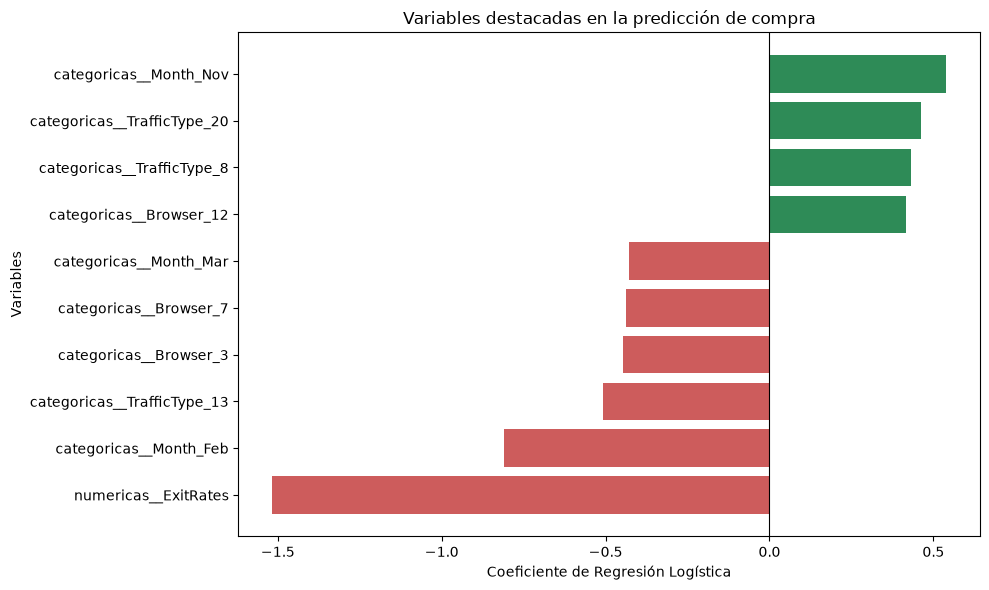

In [32]:
import matplotlib.pyplot as plt

top_10 = tabla_coeficientes.head(10).sort_values("Coeficiente")

colores = [
    "seagreen" if valor > 0 else "indianred"
    for valor in top_10["Coeficiente"]
]

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Variable"],
    top_10["Coeficiente"],
    color=colores
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Variables destacadas en la predicción de compra")
plt.xlabel("Coeficiente de Regresión Logística")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

### 7.3. Principales hallazgos del modelo

El análisis de los coeficientes de la Regresión Logística optimizada permite identificar algunas características relevantes para la predicción de compras.

Los principales hallazgos son:

- **Tasa de salida (`ExitRates`):** presenta el coeficiente negativo de mayor magnitud. Las sesiones con mayores tasas de salida tienden a recibir una menor probabilidad de compra por parte del modelo, manteniendo constantes las demás variables.

- **Estacionalidad:** noviembre presenta una asociación positiva con la predicción de compra, mientras que febrero y marzo presentan asociaciones negativas.

- **Origen del tráfico:** determinadas categorías de `TrafficType` muestran asociaciones positivas y otras negativas con la predicción de compra.

- **Navegador:** algunas categorías de `Browser` también aparecen entre los coeficientes de mayor magnitud.

Estos resultados permiten comprender mejor el comportamiento del modelo, aunque no deben interpretarse como relaciones causales.

Además, la magnitud de los coeficientes debe interpretarse con precaución, ya que las variables numéricas están estandarizadas y las categóricas se han transformado mediante One-Hot Encoding.

## 8. Evaluación final del modelo

### 8.1. Evaluación de la Regresión Logística optimizada

Tras comparar diferentes algoritmos y realizar la optimización de hiperparámetros, seleccionamos la Regresión Logística como modelo final.

Los hiperparámetros seleccionados son:

- C = 0.1.
- class_weight = "balanced".
- Umbral de decisión = 0.50.

El modelo se ha ajustado utilizando únicamente los datos de entrenamiento.

A continuación, evaluamos su rendimiento sobre el conjunto de prueba, formado por 2.466 sesiones que no han participado en el entrenamiento.

Analizaremos Accuracy, Precision, Recall, F1-score y la matriz de confusión para comprobar su capacidad de identificar compradores.

In [33]:
# Recuperar el modelo optimizado
modelo_final = grid_logistico.best_estimator_

# Evaluación final sobre los datos de prueba
funciones.evaluar_modelo(modelo_final, X_test_knn, y_test)

Accuracy: 0.631

Informe de clasificación:
              precision    recall  f1-score   support

       False       0.93      0.61      0.74      2084
        True       0.26      0.75      0.39       382

    accuracy                           0.63      2466
   macro avg       0.59      0.68      0.56      2466
weighted avg       0.83      0.63      0.68      2466


Matriz de confusión:
[[1271  813]
 [  97  285]]


ACCURACY
63,10 %
Aciertos totales

RECALL COMPRA
74,61 %
Compradores detectados

F1 COMPRA
39 %
Equilibrio de métricas

285 compradores han sido identificados correctamente.

97 compradores no han sido detectados.

813 sesiones sin compra han sido clasificadas erróneamente como compras.

1.271 sesiones sin compra han sido identificadas correctamente.

### 8.2. Interpretación de los resultados finales

La Regresión Logística optimizada ha sido evaluada sobre un conjunto de prueba de 2.466 sesiones.

Los resultados obtenidos son:

- Accuracy: 63,10 %.
- Precision de la clase compra: 26 % aproximadamente.
- Recall de la clase compra: 74,61 %.
- F1-score de la clase compra: 39 % aproximadamente.

La matriz de confusión muestra que el modelo identifica correctamente 285 de las 382 sesiones que finalizaron en compra.

Sin embargo, también clasifica erróneamente 813 sesiones sin compra como compras.

El principal punto fuerte del modelo es su capacidad para identificar una proporción elevada de compradores reales.

Su principal limitación es la baja precisión de las predicciones positivas, que puede generar falsas alarmas.

El F1-score final es similar al obtenido mediante validación cruzada, lo que sugiere un rendimiento relativamente consistente entre ambas evaluaciones.

En conclusión, el modelo constituye un prototipo útil para estudiar la intención de compra, aunque sería necesario seguir mejorándolo y validarlo con nuevos datos antes de utilizarlo en un entorno comercial real.

## 9. Guardado del modelo final

### 9.1. Exportación del modelo entrenado

Guardamos la Regresión Logística optimizada para poder reutilizarla sin necesidad de repetir el entrenamiento.

El archivo generado contiene tanto el preprocesamiento de las variables como el modelo predictivo.

Esto permitirá utilizar el modelo posteriormente en una aplicación interactiva desarrollada con Streamlit.

In [34]:
import joblib

joblib.dump(modelo_final, "modelo_compra.pkl")

print("Modelo guardado correctamente")

Modelo guardado correctamente
